In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
df = pd.read_csv("chd-201015-202131.csv")

In [3]:
df.head()

,Obs,ID,AGE,agrp,CHD
0,1,1,20,1,0
1,2,2,23,1,0
2,3,3,24,1,0
3,4,4,25,1,0
4,5,5,25,1,1


In [4]:
df.columns

Index(['Obs', 'ID', 'AGE', 'agrp', 'CHD'], dtype='str')

In [5]:
df.dropna()

,Obs,ID,AGE,agrp,CHD
0,1,1,20,1,0
1,2,2,23,1,0
2,3,3,24,1,0
3,4,4,25,1,0
4,5,5,25,1,1
...,...,...,...,...,...
95,96,96,63,8,1
96,97,97,64,8,0
97,98,98,64,8,1
98,99,99,65,8,1


In [6]:
correlation_matrix = df.drop(columns=['Obs', 'ID']).corr()
print(correlation_matrix)

           AGE      agrp       CHD
AGE   1.000000  0.988411  0.513799
agrp  0.988411  1.000000  0.510668
CHD   0.513799  0.510668  1.000000


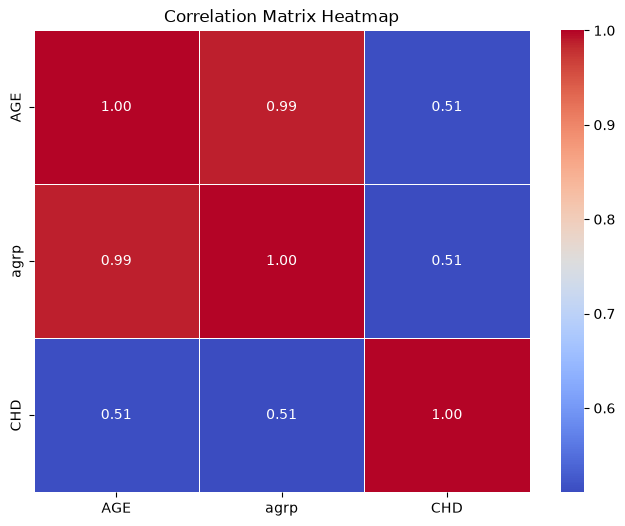

In [7]:
plt.figure(figsize=(8,6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix Heatmap")
plt.show()

In [8]:
x = df[['AGE']]

In [9]:
y = df['CHD']

In [10]:
x

,AGE
0,20
1,23
2,24
3,25
4,25
...,...
95,63
96,64
97,64
98,65


In [11]:
y

0     0
1     0
2     0
3     0
4     1
     ..
95    1
96    0
97    1
98    1
99    1
Name: CHD, Length: 100, dtype: int64

In [12]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [13]:
model = LogisticRegression()

In [14]:
model.fit(x_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [15]:
y_pred = model.predict(x_test)

In [16]:
accuracy = accuracy_score(y_test, y_pred)
print(accuracy)

0.6


In [17]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[8 3]
 [5 4]]


In [18]:
cr = classification_report(y_test, y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.62      0.73      0.67        11
           1       0.57      0.44      0.50         9

    accuracy                           0.60        20
   macro avg       0.59      0.59      0.58        20
weighted avg       0.60      0.60      0.59        20



In [19]:
print(model.coef_)
print(model.intercept_)

[[0.14592366]]
[-7.02578076]


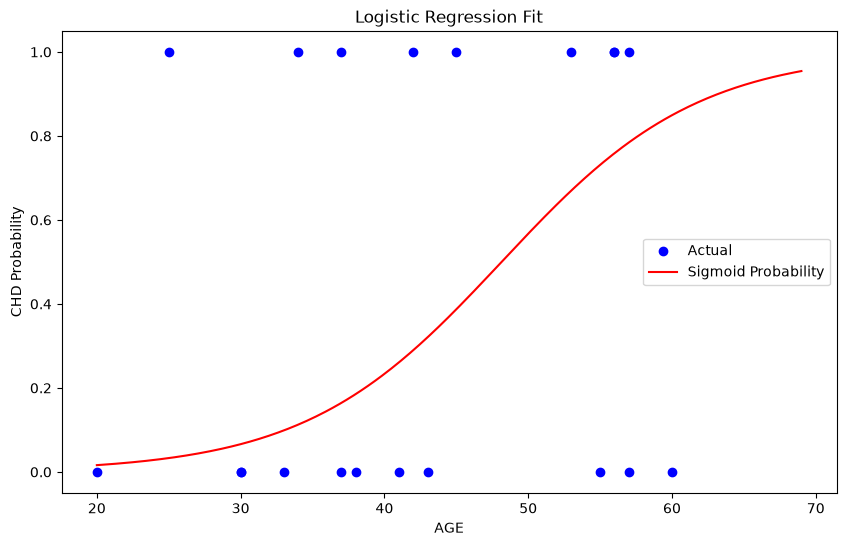

In [20]:
plt.figure(figsize=(10,6))
plt.scatter(x_test, y_test, color='blue', label='Actual')
x_range = np.linspace(x.min().iloc[0], x.max().iloc[0], 300).reshape(-1, 1)
x_range_df = pd.DataFrame(x_range, columns=x.columns)
y_prob = model.predict_proba(x_range_df)[:, 1]
plt.plot(x_range_df, y_prob, color='red', label='Sigmoid Probability')
plt.xlabel("AGE")
plt.ylabel("CHD Probability")
plt.title("Logistic Regression Fit")
plt.legend()
plt.show()

In [21]:
new_sample = pd.DataFrame([[45]], columns=x.columns)
prediction = model.predict(new_sample)
prediction_prob = model.predict_proba(new_sample)
print(f"Predicted Output: {prediction[0]}")
print(f"Predicted Probability: {prediction_prob[0]}")

Predicted Output: 0
Predicted Probability: [0.61282822 0.38717178]
